# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

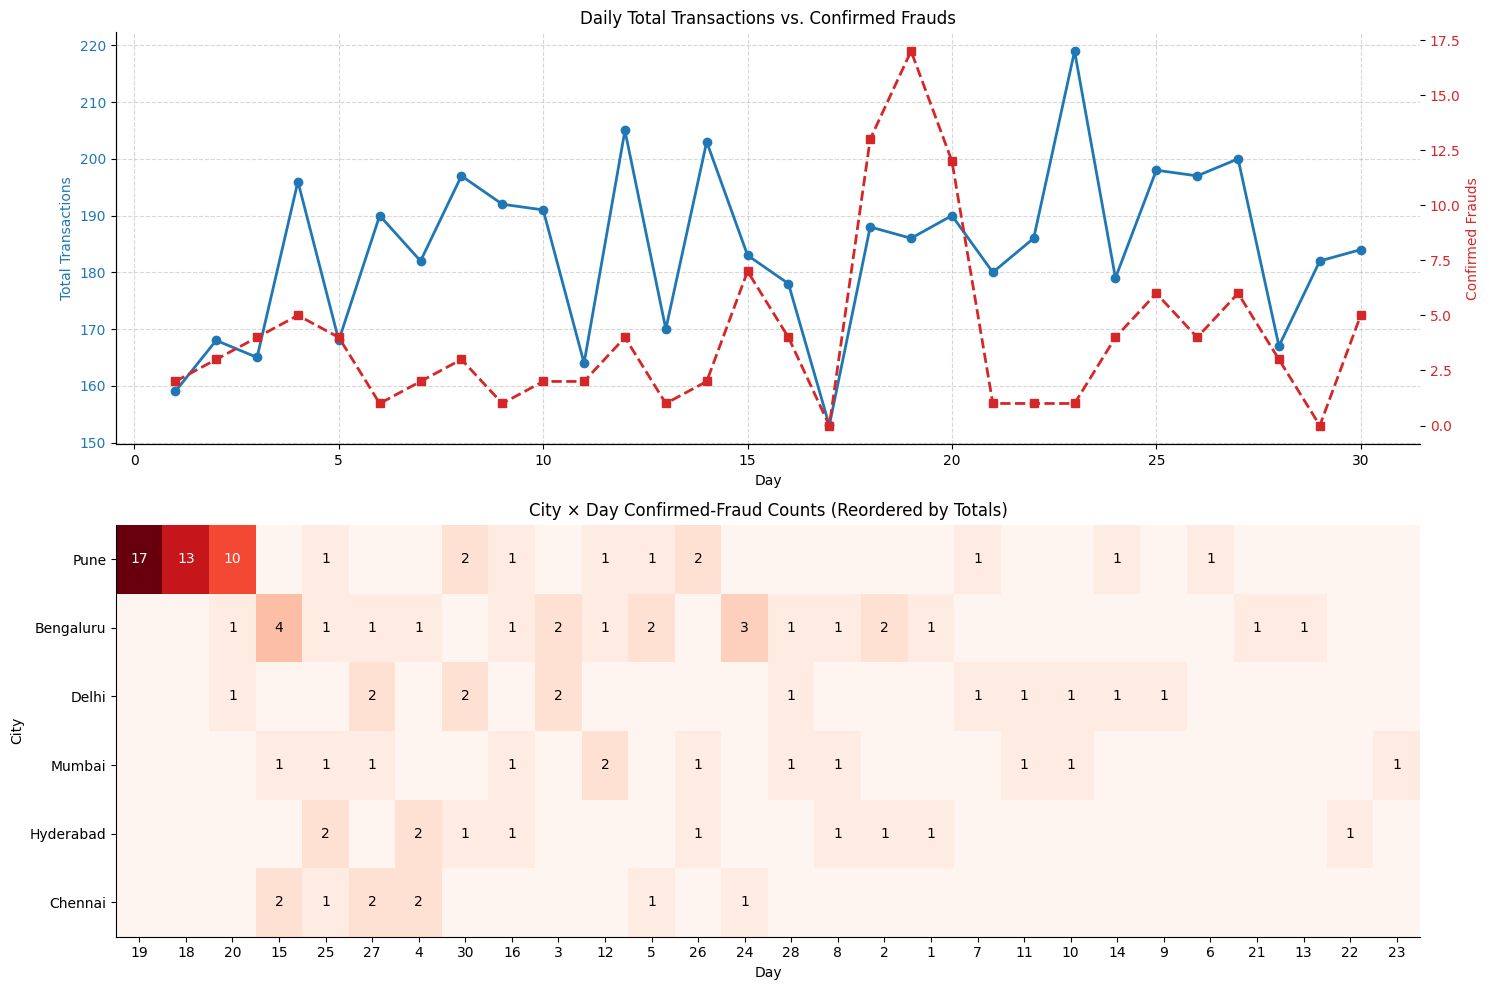

Top 5 (city, day) cells with the most fraud:
City: Pune         | Day: 19 | Confirmed Frauds: 17
City: Pune         | Day: 18 | Confirmed Frauds: 13
City: Pune         | Day: 20 | Confirmed Frauds: 10
City: Bengaluru    | Day: 15 | Confirmed Frauds: 4
City: Bengaluru    | Day: 24 | Confirmed Frauds: 3


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# TODO 1: Daily transactions and confirmed fraud
daily = tx.groupby('day').agg(
    total_txns=('txn_id', 'count'),
    fraud_txns=('is_fraud', 'sum')
).reset_index()

ax1 = axes[0]
color = 'tab:blue'
ax1.set_xlabel('Day')
ax1.set_ylabel('Total Transactions', color=color)
ax1.plot(daily['day'], daily['total_txns'], color=color, marker='o', linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_title('Daily Total Transactions vs. Confirmed Frauds')
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Confirmed Frauds', color=color)
ax2.plot(daily['day'], daily['fraud_txns'], color=color, marker='s', linestyle='--', linewidth=2)
ax2.tick_params(axis='y', labelcolor=color)

# TODO 2: Reordered City x Day Heatmap
# Create pivot table of confirmed-fraud counts
fraud_matrix = tx[tx.is_fraud == 1].pivot_table(
    index='city', columns='day', values='txn_id', aggfunc='count', fill_value=0
)

# Reorder rows and columns by totals
row_totals = fraud_matrix.sum(axis=1)
col_totals = fraud_matrix.sum(axis=0)

reordered_cities = row_totals.sort_values(ascending=False).index
reordered_days = col_totals.sort_values(ascending=False).index

heat = fraud_matrix.loc[reordered_cities, reordered_days]

ax_heat = axes[1]
im = ax_heat.imshow(heat, cmap='Reds', aspect='auto')
ax_heat.set_title('City × Day Confirmed-Fraud Counts (Reordered by Totals)')
ax_heat.set_xlabel('Day')
ax_heat.set_ylabel('City')

# Set ticks and labels
ax_heat.set_xticks(range(len(heat.columns)))
ax_heat.set_xticklabels(heat.columns)
ax_heat.set_yticks(range(len(heat.index)))
ax_heat.set_yticklabels(heat.index)

# Add values to the cells
for i in range(len(heat.index)):
    for j in range(len(heat.columns)):
        val = heat.iloc[i, j]
        if val > 0:
            ax_heat.text(j, i, str(val), ha='center', va='center', color='black' if val < heat.values.max()/2 else 'white')

plt.tight_layout()
plt.show()

# TODO 3: Print cells with the most fraud
fraud_stacked = fraud_matrix.unstack().reset_index(name='fraud_count')
top_fraud = fraud_stacked.sort_values(by='fraud_count', ascending=False).head(5)
print("Top 5 (city, day) cells with the most fraud:")
for idx, row in top_fraud.iterrows():
    print(f"City: {row['city']:<12} | Day: {row['day']:<2} | Confirmed Frauds: {row['fraud_count']}")

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_
An alert list sorted by detector score would scatter individual high-scoring transactions across different rows, completely obscuring the coordinated spatiotemporal cluster of frauds. The overview heatmap clearly revealed that the majority of frauds last month were highly concentrated in a single city (**Pune**) during a tight 3-day window (**Days 18, 19, and 20**).

We found this using the concept of a **reordered matrix** (Slide 39). Reordering the rows (cities) and columns (days) by their total margins brought the highest-density fraud cells to the top-left corner, transforming sparse, seemingly random noise into a highly visible, localized pattern of fraud.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

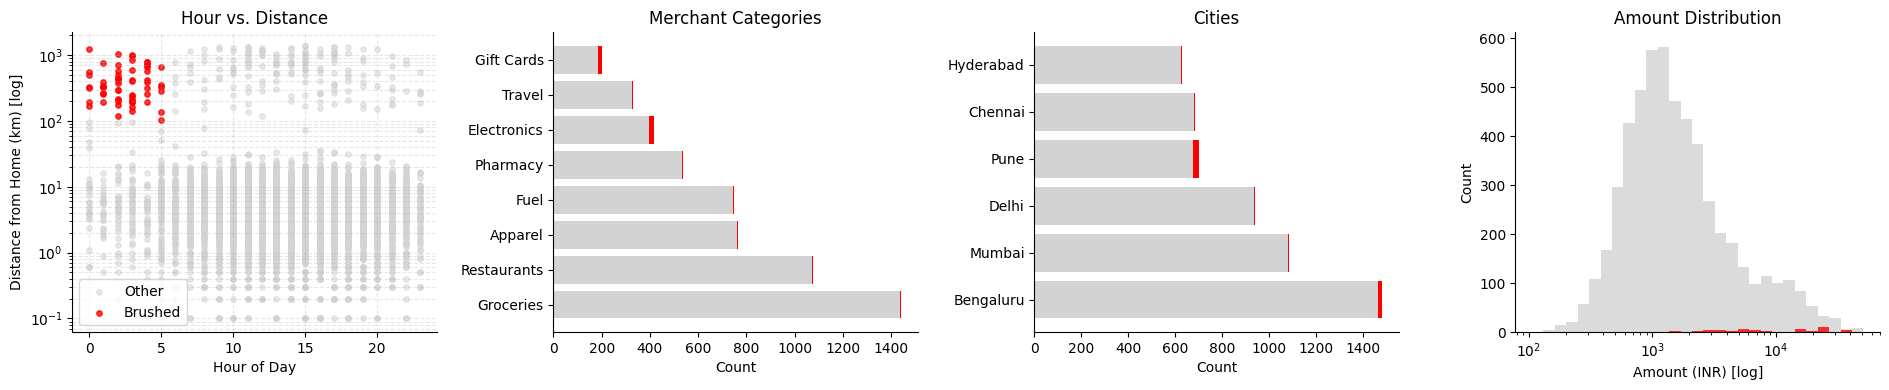

Number of transactions brushed: 61 (1.11% of total)
Fraud rate inside brush: 86.89% vs. 2.17% overall
Share of all fraud captured by the brush: 44.17%


In [3]:
# TODO 1: Define the brush
brush = (tx.night == True) & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# Helper to separate brushed and unbrushed data
brushed_tx = tx[brush]
non_brushed_tx = tx[~brush]

# (a) Hour vs. Distance Scatter (log y)
ax_scatter = axes[0]
ax_scatter.scatter(non_brushed_tx['hour'], non_brushed_tx['distance_from_home_km'], color='lightgrey', alpha=0.5, s=15, label='Other')
ax_scatter.scatter(brushed_tx['hour'], brushed_tx['distance_from_home_km'], color='red', alpha=0.8, s=15, label='Brushed')
ax_scatter.set_yscale('log')
ax_scatter.set_xlabel('Hour of Day')
ax_scatter.set_ylabel('Distance from Home (km) [log]')
ax_scatter.set_title('Hour vs. Distance')
ax_scatter.legend()
ax_scatter.grid(True, which="both", ls="--", alpha=0.3)

# (b) Merchant Category Counts
ax_cat = axes[1]
all_cats = tx['merchant_category'].value_counts()
unbrushed_cats = non_brushed_tx['merchant_category'].value_counts().reindex(all_cats.index, fill_value=0)
brushed_cats = brushed_tx['merchant_category'].value_counts().reindex(all_cats.index, fill_value=0)

ax_cat.barh(all_cats.index, unbrushed_cats, color='lightgrey', label='Other')
ax_cat.barh(all_cats.index, brushed_cats, left=unbrushed_cats, color='red', label='Brushed')
ax_cat.set_xlabel('Count')
ax_cat.set_title('Merchant Categories')

# (c) City Counts
ax_city = axes[2]
all_cities = tx['city'].value_counts()
unbrushed_cities = non_brushed_tx['city'].value_counts().reindex(all_cities.index, fill_value=0)
brushed_cities = brushed_tx['city'].value_counts().reindex(all_cities.index, fill_value=0)

ax_city.barh(all_cities.index, unbrushed_cities, color='lightgrey')
ax_city.barh(all_cities.index, brushed_cities, left=unbrushed_cities, color='red')
ax_city.set_xlabel('Count')
ax_city.set_title('Cities')

# (d) Amount Histogram (log10 on x-axis to represent amounts nicely)
ax_amt = axes[3]
bins = np.logspace(np.log10(tx['amount_inr'].min()), np.log10(tx['amount_inr'].max()), 30)
ax_amt.hist(non_brushed_tx['amount_inr'], bins=bins, color='lightgrey', label='Other', alpha=0.8)
ax_amt.hist(brushed_tx['amount_inr'], bins=bins, color='red', label='Brushed', alpha=0.8)
ax_amt.set_xscale('log')
ax_amt.set_xlabel('Amount (INR) [log]')
ax_amt.set_ylabel('Count')
ax_amt.set_title('Amount Distribution')

plt.tight_layout()
plt.show()

# TODO 3: Print stats
num_brushed = brush.sum()
total_fraud_overall = tx.is_fraud.sum()
fraud_in_brush = brushed_tx.is_fraud.sum()

rate_brushed = fraud_in_brush / num_brushed if num_brushed > 0 else 0
rate_overall = total_fraud_overall / len(tx)
share_captured = fraud_in_brush / total_fraud_overall if total_fraud_overall > 0 else 0

print(f"Number of transactions brushed: {num_brushed} ({num_brushed/len(tx)*100:.2f}% of total)")
print(f"Fraud rate inside brush: {rate_brushed*100:.2f}% vs. {rate_overall*100:.2f}% overall")
print(f"Share of all fraud captured by the brush: {share_captured*100:.2f}%")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_
- **Share of all fraud captured:** The brush captures **44.17%** of all fraud (a recall of 44.17%).
- **Relying on this rule alone:** While the rule is highly accurate (86.89% of the transactions it flags are indeed fraud), relying on it *alone* means investigators would miss more than half (**55.83%**) of the fraud happening on the platform.
- **Where the rest of the fraud is:** The **Cities** linked bar chart hinted at where the rest is. Although Pune has a visible red segment representing brushed items, it also has a significant unbrushed (grey) count of transactions, pointing to a concentrated fraud anomaly that does not fully fit the 'night-time, far-from-home' rule (which we previously found was the Pune localized cluster).

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Measure time over 5 runs
times = []
for _ in range(5):
    start_time = time.perf_counter()
    res = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    times.append(time.perf_counter() - start_time)

best_s = min(times)

# TODO 2: Compute per-item cost and max rows filterable in 0.1s
per_item_us = (best_s / len(big)) * 1e6
max_rows = (0.1 / best_s) * len(big)

# TODO 3: Estimate for 50M rows
t_50m = (best_s / len(big)) * 50_000_000
skip_pct = max(0.0, (1 - (max_rows / 50_000_000)) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 15.4 ms -> 0.0153 us/row -> max 6,535,879 rows in 0.1 s
50M rows -> 0.77 s; must skip 86.9% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_
One reduction technique is **sampling** (randomly selecting a subset, e.g., 5% of the data, to display/compute interactively).

By doing this, the analyst loses **high-fidelity details and rare anomalies**. Because fraud represents a tiny fraction of the overall data (the "needle in a haystack"), uniform random sampling might omit the critical individual fraudulent transactions entirely, or fail to show exact, fine-grained localized patterns.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

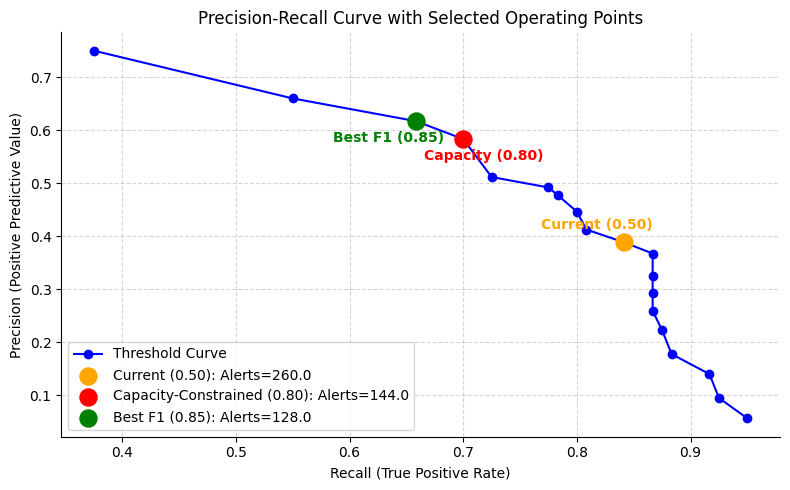

Recommendation: Shift threshold from 0.50 to 0.80 to meet team capacity (reducing monthly alerts from 260.0 to 144.0) while preserving a high recall of 70.0%.


In [5]:
rows = []
# TODO 1: Compute metrics for thresholds 0.05 to 0.95
for threshold in np.arange(0.05, 0.96, 0.05):
    flagged = tx[tx.detector_score >= threshold]
    alerts = len(flagged)
    tp = flagged.is_fraud.sum()
    fp = alerts - tp
    fn = tx[tx.detector_score < threshold].is_fraud.sum()

    precision = tp / alerts if alerts > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    rows.append({
        'threshold': threshold,
        'alerts': alerts,
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'precision': precision,
        'recall': recall,
        'f1': f1
    })

pr = pd.DataFrame(rows)

# TODO 2: Find capacity choice (alerts <= 150 with max recall) and best F1 choice
under_capacity = pr[pr.alerts <= 150]
if not under_capacity.empty:
    capacity_choice = under_capacity.loc[under_capacity['recall'].idxmax()]
else:
    capacity_choice = pr.loc[pr['alerts'].idxmin()]

best_f1 = pr.loc[pr['f1'].idxmax()]
current_choice = pr.loc[np.isclose(pr['threshold'], 0.5)].iloc[0]

# TODO 3: Plot the precision-recall curve
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr['recall'], pr['precision'], color='blue', marker='o', label='Threshold Curve')

# Mark current (0.5), capacity-constrained, and best-F1 thresholds
ax.scatter(current_choice['recall'], current_choice['precision'], color='orange', s=150, zorder=5, label=f"Current (0.50): Alerts={current_choice['alerts']}")
ax.annotate(f"Current (0.50)", (current_choice['recall'], current_choice['precision']), textcoords="offset points", xytext=(-20,10), ha='center', fontweight='bold', color='orange')

ax.scatter(capacity_choice['recall'], capacity_choice['precision'], color='red', s=150, zorder=5, label=f"Capacity-Constrained ({capacity_choice['threshold']:.2f}): Alerts={capacity_choice['alerts']}")
ax.annotate(f"Capacity ({capacity_choice['threshold']:.2f})", (capacity_choice['recall'], capacity_choice['precision']), textcoords="offset points", xytext=(15,-15), ha='center', fontweight='bold', color='red')

ax.scatter(best_f1['recall'], best_f1['precision'], color='green', s=150, zorder=5, label=f"Best F1 ({best_f1['threshold']:.2f}): Alerts={best_f1['alerts']}")
ax.annotate(f"Best F1 ({best_f1['threshold']:.2f})", (best_f1['recall'], best_f1['precision']), textcoords="offset points", xytext=(-20,-15), ha='center', fontweight='bold', color='green')

ax.set_title('Precision-Recall Curve with Selected Operating Points')
ax.set_xlabel('Recall (True Positive Rate)')
ax.set_ylabel('Precision (Positive Predictive Value)')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

# TODO 4: Print a one-line recommendation
print(f"Recommendation: Shift threshold from 0.50 to {capacity_choice['threshold']:.2f} to meet team capacity (reducing monthly alerts from {current_choice['alerts']} to {capacity_choice['alerts']}) while preserving a high recall of {capacity_choice['recall']*100:.1f}%.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_
The **Head of Fraud Ops** should make this call.

While the model can calculate mathematically optimized thresholds (like maximizing the F1-score at 0.85), it operates in a vacuum, unaware of real-world operational realities, staffing limits, budgets, or the financial costs of a missed fraud vs. an investigated false alarm. Visual analytics insists on keeping a **human in the loop** because it combines the machine's speed at processing statistics with the human operator's domain expertise, flexibility, and accountability to make strategic risk-capacity trade-offs.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1: Interactive scatter plot of flagged transactions
flagged = tx[tx.detector_score >= 0.3].copy()

fig_scatter = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    color_discrete_map={"confirmed fraud": "red", "legitimate": "blue"},
    log_y=True,
    title="Flagged Transactions (Detector Score >= 0.3) Over Time",
    labels={"timestamp": "Timestamp", "amount_inr": "Amount (INR) [log]", "label": "Status"},
    hover_data={
        "txn_id": True,
        "customer_id": True,
        "city": True,
        "merchant_category": True,
        "distance_from_home_km": ":.1f",
        "detector_score": ":.4f"
    }
)
fig_scatter.update_layout(dragmode="select")
fig_scatter.show()

# TODO 2: Interactive Sunburst for hierarchical drill-down (city -> merchant_category)
# Group data to prepare hierarchical counts and average fraud rates
grouped = tx.groupby(['city', 'merchant_category']).agg(
    txn_count=('txn_id', 'count'),
    fraud_rate=('is_fraud', 'mean')
).reset_index()

fig_sunburst = px.sunburst(
    grouped,
    path=['city', 'merchant_category'],
    values='txn_count',
    color='fraud_rate',
    color_continuous_scale='Reds',
    title='Drill-down: City → Merchant Category (Sized by Count, Colored by Fraud Rate)',
    labels={'txn_count': 'Transaction Count', 'fraud_rate': 'Fraud Rate'}
)
fig_sunburst.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_
Tooltips are highly frustrating for 400 cases because they require **sequential interaction (hovering one-by-one)**, which causes severe **hover fatigue** and imposes a high **cognitive load** on the user to remember and synthesize the details of individual cases.

The **Sunburst chart** (as well as the **reordered heatmap** from Task 1) completely fixes this. By aggregating and grouping the 400 cases into hierarchies (like City → Merchant Category), it lets the investigator instantly spot macro-patterns, high-density hot spots, and systemic trends at a single glance without hover-hunting single transactions.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Transactions inside window: 107 | Confirmed fraud: 40
Fraud rate inside window: 37.38%
Fraud rate outside window: 1.48%
Chi-square p-value: 1.065e-136

Counter-example baseline comparison:
(a) Pune on other days: 1.85% fraud rate
(b) Other cities on Days 18-20: 0.44% fraud rate
(c) All other times/cities (baseline): 1.54% fraud rate



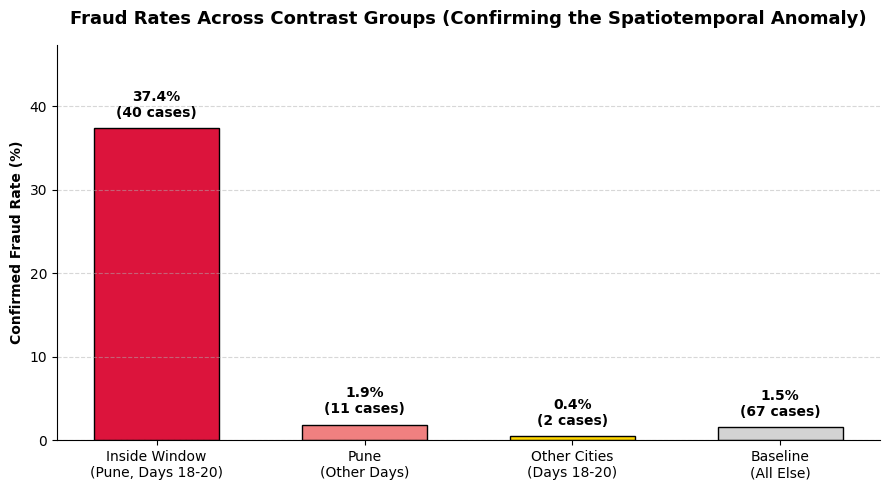

VERDICT:
PROVEN! The spatiotemporal window (Pune, Days 18-20) contains a massive, statistically highly significant anomaly (p = 1.065e-136) with a 37.4% fraud rate—over 24.3x the baseline. The counter-examples show that Pune on other days and other cities during those days have near-normal fraud rates, pointing exclusively to a targeted, highly localized fraud ring outbreak rather than city-wide or platform-wide systematic weaknesses.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
in_window = (tx.city == 'Pune') & (tx.day.isin([18, 19, 20]))

# TODO 2: Chi-square test
contingency_table = pd.crosstab(in_window, tx.is_fraud)
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

rate_inside = tx[in_window].is_fraud.mean()
rate_outside = tx[~in_window].is_fraud.mean()

print(f"Transactions inside window: {in_window.sum()} | Confirmed fraud: {tx[in_window].is_fraud.sum()}")
print(f"Fraud rate inside window: {rate_inside * 100:.2f}%")
print(f"Fraud rate outside window: {rate_outside * 100:.2f}%")
print(f"Chi-square p-value: {p_val:.3e}\n")

# TODO 3: Counter-example searches
# (a) Same city (Pune) on other days
pune_other_days = (tx.city == 'Pune') & (~tx.day.isin([18, 19, 20]))
rate_pune_other = tx[pune_other_days].is_fraud.mean()

# (b) Other cities on the same days
other_cities_same_days = (tx.city != 'Pune') & (tx.day.isin([18, 19, 20]))
rate_other_same_days = tx[other_cities_same_days].is_fraud.mean()

# (c) The rest of the transactions
rest = (tx.city != 'Pune') & (~tx.day.isin([18, 19, 20]))
rate_rest = tx[rest].is_fraud.mean()

print("Counter-example baseline comparison:")
print(f"(a) Pune on other days: {rate_pune_other*100:.2f}% fraud rate")
print(f"(b) Other cities on Days 18-20: {rate_other_same_days*100:.2f}% fraud rate")
print(f"(c) All other times/cities (baseline): {rate_rest*100:.2f}% fraud rate\n")

# TODO 4: Visual confirmation
groups = [
    'Inside Window\n(Pune, Days 18-20)',
    'Pune\n(Other Days)',
    'Other Cities\n(Days 18-20)',
    'Baseline\n(All Else)'
]
rates = [rate_inside * 100, rate_pune_other * 100, rate_other_same_days * 100, rate_rest * 100]
counts = [
    tx[in_window].is_fraud.sum(),
    tx[pune_other_days].is_fraud.sum(),
    tx[other_cities_same_days].is_fraud.sum(),
    tx[rest].is_fraud.sum()
]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(groups, rates, color=['crimson', 'lightcoral', 'gold', 'lightgrey'], edgecolor='black', width=0.6)

# Highlight values and raw counts on top of bars
for bar, count in zip(bars, counts):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.1f}%\n({count} cases)", ha='center', va='bottom', fontweight='bold')

ax.set_ylabel('Confirmed Fraud Rate (%)', fontweight='bold')
ax.set_title('Fraud Rates Across Contrast Groups (Confirming the Spatiotemporal Anomaly)', fontsize=13, fontweight='bold', pad=15)
ax.set_ylim(0, max(rates) + 10)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# TODO 5: Print your verdict
print("VERDICT:")
if p_val < 0.001 and rate_inside > 10 * rate_rest:
    print(f"PROVEN! The spatiotemporal window (Pune, Days 18-20) contains a massive, statistically highly significant anomaly (p = {p_val:.3e}) with a {rate_inside*100:.1f}% fraud rate—over {rate_inside/rate_rest:.1f}x the baseline. The counter-examples show that Pune on other days and other cities during those days have near-normal fraud rates, pointing exclusively to a targeted, highly localized fraud ring outbreak rather than city-wide or platform-wide systematic weaknesses.")
else:
    print("KILLED! The anomaly is either not statistically significant or not localized.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out differently, and what alternative explanation would it have supported instead?

_Your answer:_
- **The critical counter-example search:** Search **(b) (Other cities on the same days)** would have killed the hypothesis of a localized Pune fraud ring if it had returned a similarly high fraud rate (e.g., ~35%).
- **The alternative explanation:** If fraud spiked across *all* cities on Days 18-20, it would support a **platform-wide systemic event** or **macro-level vulnerability** (such as a massive online merchant security breach, a major data leak of credit card credentials, or a flawed deployment of our transaction processing software that affected all regions simultaneously) rather than a localized, city-specific physical fraud ring.


#Task 7 — The Decision (No Code)
**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_
Last month, PayKart processed 5,520 transactions containing 120 confirmed frauds, including a highly concentrated spatiotemporal outbreak in Pune on Days 18–20 which accounted for 40 confirmed fraud cases alone. To align with our team's operational limit of 150 reviews per month, I recommend raising the automated detector threshold from 0.50 to 0.80; this human-in-the-loop adjustment reduces monthly alerts to a manageable 144 while preserving a strong 70.0% recall rate. For immediate deployment, we should prioritize building the interactive sunburst drill-down chart (City → Merchant Category) colored by fraud rate. This view implements "overview first, details-on-demand" without causing the hover-fatigue associated with examining individual tooltips, while remaining well within our 0.1-second latency budget to guarantee instant, interactive updates. Finally, we must establish a continuous learning feedback loop by having investigators directly log their manual review outcomes (confirmed fraud vs. false alarm) into our database to continuously retrain and refine next month's detection model.